In [55]:
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import sklearn
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

# Stage 1: Air-quality forecasting

**Dataset source:** [UCI Air Quality dataset](https://archive.ics.uci.edu/dataset/360/air+quality), DOI: [10.24432/C59K5F](https://doi.org/10.24432/C59K5F). The workspace CSV is `AirQualityUCI.csv`.

**Forecast target:** `C6H6(GT)`, the reference analyzer's hourly averaged benzene concentration, measured in **micrograms per cubic metre (µg/m³)**. Inputs are the seven project-selected features; the task is a 72-hour lookback to predict the next 24 hours.

**Frequency and resampling:** observations are hourly; this notebook does not resample the series. It audits the supplied file's actual timestamp coverage and gaps below. The source marks missing sensor/reference readings with `-200`. Input gaps are forward-filled, with training-only medians for leading gaps; missing benzene target labels remain missing and are excluded from training loss and validation metrics.

**Evaluation boundary:** use validation data for model comparison and grid-search selection. **Do not evaluate on the test set in Stage 1.**

In [56]:
# 1. Load data correctly
df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',')
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [57]:
# Clean trailing empty columns if present
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

In [58]:
# 2. Create a chronological datetime index before splitting.
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce",
)
df = df.dropna(subset=["DateTime"]).set_index("DateTime").sort_index()
df = df.drop(columns=["Date", "Time"])

print(f"Rows after removing invalid timestamps: {len(df)}")
print(f"Time span: {df.index.min()} to {df.index.max()}")
print(f"Chronological order: {df.index.is_monotonic_increasing}")

Rows after removing invalid timestamps: 9357
Time span: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Chronological order: True


In [59]:
# 3. Chronological 60/20/20 split before imputation or scaling.
train_size = int(len(df) * 0.6)
val_size = int(len(df) * 0.2)

train_df = df.iloc[:train_size].copy()
val_df = df.iloc[train_size:train_size + val_size].copy()
test_df = df.iloc[train_size + val_size:].copy()

print(f"Train shape: {train_df.shape}")
print(f"Validation shape: {val_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Train ends: {train_df.index[-1]}")
print(f"Validation ends: {val_df.index[-1]}")
print(f"Test starts: {test_df.index[0]}")

assert train_df.index.max() < val_df.index.min()
assert val_df.index.max() < test_df.index.min()

Train shape: (5614, 13)
Validation shape: (1871, 13)
Test shape: (1872, 13)
Train ends: 2004-10-30 15:00:00
Validation ends: 2005-01-16 14:00:00
Test starts: 2005-01-16 15:00:00


In [60]:
# 4. Audit missingness and impute inputs without filling forecast labels.
train_missing = train_df.replace(-200, np.nan)
val_missing = val_df.replace(-200, np.nan)
test_missing = test_df.replace(-200, np.nan)

missing_summary = pd.DataFrame({
    "Train missing (%)": train_missing.isna().mean() * 100,
    "Validation missing (%)": val_missing.isna().mean() * 100,
    "Test missing (%)": test_missing.isna().mean() * 100,
}).round(2)
display(missing_summary.sort_values("Train missing (%)", ascending=False))

# Keep the project decision to exclude the mostly-missing NMHC(GT) feature.
columns_to_drop = ["NMHC(GT)"]
train_missing = train_missing.drop(columns=columns_to_drop)
val_missing = val_missing.drop(columns=columns_to_drop)
test_missing = test_missing.drop(columns=columns_to_drop)

# Do not impute target labels: missing benzene readings stay NaN and are masked
# from training loss and validation metrics in the window-building step.
TARGET_COL = "C6H6(GT)"
features = ["C6H6(GT)", "PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S5(O3)", "T", "RH", "AH"]
train_target_observed = train_missing[TARGET_COL].copy()
val_target_observed = val_missing[TARGET_COL].copy()

# Fit fallback medians on training features only. Forward-fill uses past
# observations; the median handles only leading gaps with no prior value.
train_feature_raw = train_missing[features]
val_feature_raw = val_missing[features]
test_feature_raw = test_missing[features]
training_feature_medians = train_feature_raw.median()

def causal_impute_inputs(frame, fallback_values):
    return frame.ffill().fillna(fallback_values)

train_processed = causal_impute_inputs(train_feature_raw, training_feature_medians)
val_processed = causal_impute_inputs(val_feature_raw, training_feature_medians)
test_processed = causal_impute_inputs(test_feature_raw, training_feature_medians)

print("Missing target observations retained for masking:", {
    "train": int(train_target_observed.isna().sum()),
    "validation": int(val_target_observed.isna().sum()),
})
print("Remaining missing input features:", {
    "train": int(train_processed.isna().sum().sum()),
    "validation": int(val_processed.isna().sum().sum()),
    "test": int(test_processed.isna().sum().sum()),
})

,Train missing (%),Validation missing (%),Test missing (%)
NMHC(GT),83.72,100.00,100.00
CO(GT),25.61,8.23,4.86
NO2(GT),24.62,10.80,3.10
NOx(GT),24.56,10.80,3.10
PT08.S1(CO),2.64,7.06,4.59
C6H6(GT),2.64,7.06,4.59
PT08.S2(NMHC),2.64,7.06,4.59
PT08.S3(NOx),2.64,7.06,4.59
PT08.S4(NO2),2.64,7.06,4.59
PT08.S5(O3),2.64,7.06,4.59


Missing target observations retained for masking: {'train': 148, 'validation': 132}
Remaining missing input features: {'train': 0, 'validation': 0, 'test': 0}


In [61]:
# 5. Scale inputs using training statistics; preserve observed target masks.
LOOKBACK = 72
HORIZON = 24
target_idx = features.index(TARGET_COL)

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_processed[features])
val_scaled = scaler.transform(val_processed[features])
test_scaled = scaler.transform(test_processed[features])
target_mean = scaler.mean_[target_idx]
target_scale = scaler.scale_[target_idx]

train_target_scaled = (train_target_observed.to_numpy() - target_mean) / target_scale
val_target_scaled = (val_target_observed.to_numpy() - target_mean) / target_scale

def create_labeled_windows(input_data, target_data, lookback=LOOKBACK, horizon=HORIZON):
    X, y, target_masks = [], [], []
    for start in range(len(input_data) - lookback - horizon + 1):
        target_window = target_data[start + lookback : start + lookback + horizon]
        X.append(input_data[start : start + lookback])
        y.append(target_window)
        target_masks.append(np.isfinite(target_window))
    return np.asarray(X), np.asarray(y), np.asarray(target_masks)

# Each split is windowed independently; NaN targets remain masked, not imputed.
X_train, y_train, train_target_mask = create_labeled_windows(train_scaled, train_target_scaled)
X_val, y_val, val_target_mask = create_labeled_windows(val_scaled, val_target_scaled)
# Prepare test inputs only; do not create test labels or calculate test metrics in Stage 1.
X_test = np.asarray([
    test_scaled[start : start + LOOKBACK]
    for start in range(len(test_scaled) - LOOKBACK - HORIZON + 1)
])

print(f"Feature order: {features}")
print(f"Target: {TARGET_COL}; lookback: {LOOKBACK} hours; horizon: {HORIZON} hours")
print(f"Train: X={X_train.shape}, y={y_train.shape}; observed labels={int(train_target_mask.sum()):,}/{train_target_mask.size:,}")
print(f"Validation: X={X_val.shape}, y={y_val.shape}; observed labels={int(val_target_mask.sum()):,}/{val_target_mask.size:,}")
print(f"Test inputs prepared: X={X_test.shape}; test labels and metrics remain unused.")

assert X_train.shape[1:] == (LOOKBACK, len(features))
assert y_train.shape[1] == HORIZON
assert X_val.shape[1:] == X_train.shape[1:]
assert y_val.shape == val_target_mask.shape
assert not np.isfinite(y_train[~train_target_mask]).any()
assert not np.isfinite(y_val[~val_target_mask]).any()
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()

Feature order: ['C6H6(GT)', 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Target: C6H6(GT); lookback: 72 hours; horizon: 24 hours
Train: X=(5519, 72, 7), y=(5519, 24); observed labels=128,904/132,456
Validation: X=(1776, 72, 7), y=(1776, 24); observed labels=39,456/42,624
Test inputs prepared: X=(1777, 72, 7); test labels and metrics remain unused.


Rows: 9,357
Coverage: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Native sampling interval (mode): 0 days 01:00:00
Duplicate timestamps: 0
Intervals longer than the native interval: 0


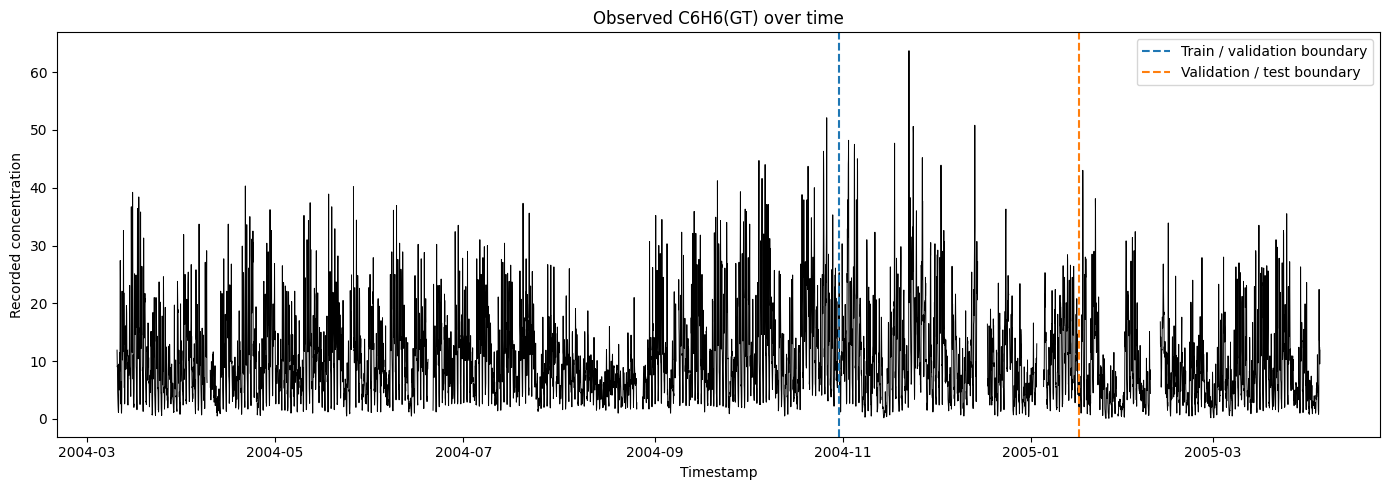

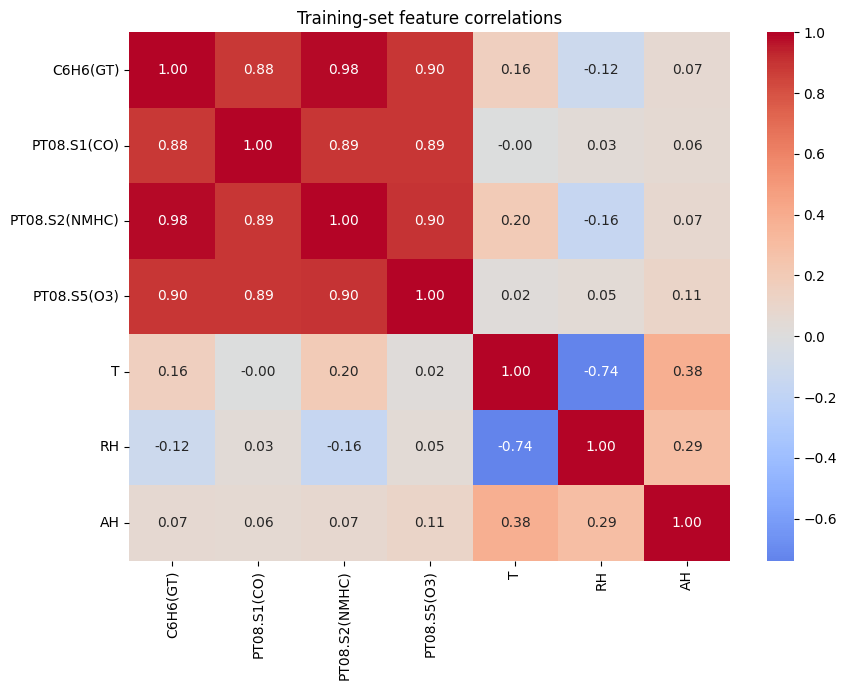

In [62]:
# 6. Dataset timestamp audit and exploratory figures.
time_deltas = df.index.to_series().diff().dropna()
native_interval = time_deltas.mode().iloc[0]
long_gaps = time_deltas[time_deltas > native_interval]

print(f"Rows: {len(df):,}")
print(f"Coverage: {df.index.min()} to {df.index.max()}")
print(f"Native sampling interval (mode): {native_interval}")
print(f"Duplicate timestamps: {int(df.index.duplicated().sum())}")
print(f"Intervals longer than the native interval: {len(long_gaps)}")
if not long_gaps.empty:
    print(f"Longest interval: {time_deltas.max()}")

# Figure 1: observed benzene series; -200 is shown as missing, not as a measurement.
target_series = df[TARGET_COL].replace(-200, np.nan)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(target_series.index, target_series, color="black", linewidth=0.7)
ax.axvline(train_df.index[-1], color="tab:blue", linestyle="--", label="Train / validation boundary")
ax.axvline(val_df.index[-1], color="tab:orange", linestyle="--", label="Validation / test boundary")
ax.set_title(f"Observed {TARGET_COL} over time")
ax.set_xlabel("Timestamp")
ax.set_ylabel("Recorded concentration")
ax.legend()
fig.tight_layout()
plt.show()

# Figure 2: correlations calculated from training observations only (pairwise complete cases).
train_correlations = train_missing[features].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train_correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Training-set feature correlations")
fig.tight_layout()
plt.show()

In [63]:
# 7. Seasonal-naive baseline: repeat the most recent 24-hour target pattern.
# Accuracy and F1 are classification metrics, so they are not appropriate for this
# continuous-value forecasting task. Use RMSE and MAE in the original target units.
import time

baseline_start = time.perf_counter()
baseline_pred_scaled = X_val[:, -HORIZON:, target_idx]
baseline_prediction_seconds = time.perf_counter() - baseline_start

# Undo target standardization so the reported errors are in the recorded units.
target_mean = scaler.mean_[target_idx]
target_scale = scaler.scale_[target_idx]
y_val_original = y_val * target_scale + target_mean
baseline_pred_original = baseline_pred_scaled * target_scale + target_mean

observed_val = val_target_mask
baseline_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], baseline_pred_original[observed_val]))
baseline_mae = mean_absolute_error(y_val_original[observed_val], baseline_pred_original[observed_val])

print("Baseline predictions and validation targets have shape:", baseline_pred_original.shape)
print(f"Metrics use only observed validation targets: {int(observed_val.sum()):,}/{observed_val.size:,} target values.")

Baseline predictions and validation targets have shape: (1776, 24)
Metrics use only observed validation targets: 39,456/42,624 target values.


In [64]:
# 8. Train the MLP on training windows and evaluate once on validation windows.
import random
import time
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 64
epochs = 15
learning_rate = 0.001

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(np.nan_to_num(y_train, nan=0.0), dtype=torch.float32),
        torch.tensor(train_target_mask, dtype=torch.float32),
    ),
    batch_size=batch_size,
    shuffle=True,
)

class TimeSeriesMLP(nn.Module):
    def __init__(self, lookback, num_features, horizon):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * num_features, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        return self.network(x)

mlp_model = TimeSeriesMLP(LOOKBACK, len(features), HORIZON).to(device)
mlp_parameter_count = sum(parameter.numel() for parameter in mlp_model.parameters() if parameter.requires_grad)
def masked_mse_loss(predictions, targets, target_mask):
    squared_errors = (predictions - targets).square() * target_mask
    return squared_errors.sum() / target_mask.sum().clamp_min(1.0)

criterion = masked_mse_loss
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=learning_rate)

# Only training batches contribute gradients or optimizer updates.
mlp_training_start = time.perf_counter()
for epoch in range(epochs):
    mlp_model.train()
    for batch_x, batch_y, batch_mask in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        batch_mask = batch_mask.to(device)

        optimizer.zero_grad()
        predictions = mlp_model(batch_x)
        loss = criterion(predictions, batch_y, batch_mask)
        loss.backward()
        optimizer.step()
mlp_training_seconds = time.perf_counter() - mlp_training_start

# Validation is evaluation-only; it does not update model parameters.
mlp_model.eval()
validation_start = time.perf_counter()
with torch.no_grad():
    val_tensor = torch.tensor(X_val, dtype=torch.float32, device=device)
    mlp_pred_scaled = mlp_model(val_tensor).cpu().numpy()
mlp_prediction_seconds = time.perf_counter() - validation_start

mlp_pred_original = mlp_pred_scaled * target_scale + target_mean
mlp_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], mlp_pred_original[observed_val]))
mlp_mae = mean_absolute_error(y_val_original[observed_val], mlp_pred_original[observed_val])

print(f"Trained on {len(X_train)} training windows; evaluated on {len(X_val)} validation windows.")

Trained on 5519 training windows; evaluated on 1776 validation windows.


In [65]:
# 9. Train the 1D CNN on training windows and evaluate on validation windows.
# Reset the seed so this model's initialization and batch order are reproducible.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

class TimeSeriesCNN(nn.Module):
    def __init__(self, num_features, horizon):
        super().__init__()
        self.conv1 = nn.Conv1d(
            in_channels=num_features,
            out_channels=64,
            kernel_size=3,
            padding=1,
        )
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.head = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        # Input is [batch, lookback, features]; Conv1d expects channels second.
        x = x.permute(0, 2, 1)
        x = self.relu(self.conv1(x))
        x = self.pool(x).squeeze(-1)
        return self.head(x)

cnn_model = TimeSeriesCNN(len(features), HORIZON).to(device)
cnn_parameter_count = sum(parameter.numel() for parameter in cnn_model.parameters() if parameter.requires_grad)
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=learning_rate)

# Use the same training windows, loss, optimizer, epochs, and batch size as the MLP.
cnn_training_start = time.perf_counter()
for epoch in range(epochs):
    cnn_model.train()
    for batch_x, batch_y, batch_mask in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        batch_mask = batch_mask.to(device)

        cnn_optimizer.zero_grad()
        predictions = cnn_model(batch_x)
        loss = criterion(predictions, batch_y, batch_mask)
        loss.backward()
        cnn_optimizer.step()
cnn_training_seconds = time.perf_counter() - cnn_training_start

# Validation is evaluation-only and does not update CNN parameters.
cnn_model.eval()
cnn_validation_start = time.perf_counter()
with torch.no_grad():
    val_tensor = torch.tensor(X_val, dtype=torch.float32, device=device)
    cnn_pred_scaled = cnn_model(val_tensor).cpu().numpy()
cnn_prediction_seconds = time.perf_counter() - cnn_validation_start

cnn_pred_original = cnn_pred_scaled * target_scale + target_mean
cnn_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], cnn_pred_original[observed_val]))
cnn_mae = mean_absolute_error(y_val_original[observed_val], cnn_pred_original[observed_val])

print(f"Trained on {len(X_train)} training windows; evaluated on {len(X_val)} validation windows.")

# Compare the baseline and both neural models using validation metrics.
cnn_stage_comparison = pd.DataFrame([
    {
        "Model": "Seasonal naive",
        "Validation RMSE": baseline_rmse,
        "Validation MAE": baseline_mae,
        "Trainable parameters": 0,
        "Training time (seconds)": 0.0,
        "Validation prediction time (seconds)": baseline_prediction_seconds,
    },
    {
        "Model": "MLP",
        "Validation RMSE": mlp_rmse,
        "Validation MAE": mlp_mae,
        "Trainable parameters": mlp_parameter_count,
        "Training time (seconds)": mlp_training_seconds,
        "Validation prediction time (seconds)": mlp_prediction_seconds,
    },
    {
        "Model": "1D CNN",
        "Validation RMSE": cnn_rmse,
        "Validation MAE": cnn_mae,
        "Trainable parameters": cnn_parameter_count,
        "Training time (seconds)": cnn_training_seconds,
        "Validation prediction time (seconds)": cnn_prediction_seconds,
    },
]).sort_values("Validation RMSE").reset_index(drop=True)

display(cnn_stage_comparison.round(4))
print(f"Lowest validation RMSE among these models: {cnn_stage_comparison.iloc[0]['Model']}.")

Trained on 5519 training windows; evaluated on 1776 validation windows.


,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds)
0,MLP,6.7643,4.6984,74456,6.4697,0.0049
1,Seasonal naive,8.1259,5.6957,0,0.0000,0.0010
2,1D CNN,8.1630,6.2237,7128,14.0718,0.0530


Lowest validation RMSE among these models: MLP.


In [66]:
# 11. Tune the MLP using validation RMSE; training batches alone update weights.
# Fixed budget: 4 configurations x 15 epochs; dropout=0.2 and batch size=64.
from copy import deepcopy

learning_rates = [0.001, 0.0005]
hidden_layer_options = [(128, 64), (256, 128)]
grid_epochs = epochs
grid_batch_size = batch_size
grid_dropout = 0.2
grid_results = []
best_mlp_val_rmse = float("inf")
best_mlp_config = None
best_mlp_state = None

class GridSearchMLP(nn.Module):
    def __init__(self, lookback, num_features, horizon, hidden_sizes, dropout):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * num_features, hidden_sizes[0]),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_sizes[0], hidden_sizes[1]),
            nn.ReLU(),
            nn.Linear(hidden_sizes[1], horizon),
        )

    def forward(self, x):
        return self.network(x)

for trial, (lr, hidden_sizes) in enumerate(
    [(lr, widths) for lr in learning_rates for widths in hidden_layer_options],
    start=1,
):
    trial_seed = SEED + trial
    random.seed(trial_seed)
    np.random.seed(trial_seed)
    torch.manual_seed(trial_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(trial_seed)

    loader_generator = torch.Generator().manual_seed(trial_seed)
    trial_train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(np.nan_to_num(y_train, nan=0.0), dtype=torch.float32),
            torch.tensor(train_target_mask, dtype=torch.float32),
        ),
        batch_size=grid_batch_size,
        shuffle=True,
        generator=loader_generator,
    )
    trial_model = GridSearchMLP(LOOKBACK, len(features), HORIZON, hidden_sizes, grid_dropout).to(device)
    trial_parameters = sum(p.numel() for p in trial_model.parameters() if p.requires_grad)
    trial_optimizer = torch.optim.Adam(trial_model.parameters(), lr=lr)

    trial_start = time.perf_counter()
    for epoch in range(grid_epochs):
        trial_model.train()
        for batch_x, batch_y, batch_mask in trial_train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            batch_mask = batch_mask.to(device)
            trial_optimizer.zero_grad()
            trial_loss = criterion(trial_model(batch_x), batch_y, batch_mask)
            trial_loss.backward()
            trial_optimizer.step()
    trial_training_seconds = time.perf_counter() - trial_start

    trial_model.eval()
    with torch.no_grad():
        trial_prediction_scaled = trial_model(val_tensor).cpu().numpy()
    trial_prediction_original = trial_prediction_scaled * target_scale + target_mean
    trial_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], trial_prediction_original[observed_val]))
    trial_mae = mean_absolute_error(y_val_original[observed_val], trial_prediction_original[observed_val])

    config = {
        "learning_rate": lr,
        "hidden_sizes": hidden_sizes,
        "dropout": grid_dropout,
        "batch_size": grid_batch_size,
        "epochs": grid_epochs,
    }
    grid_results.append({
        "Trial": trial,
        "Learning rate": lr,
        "Hidden layers": str(hidden_sizes),
        "Dropout": grid_dropout,
        "Batch size": grid_batch_size,
        "Epochs": grid_epochs,
        "Validation RMSE": trial_rmse,
        "Validation MAE": trial_mae,
        "Trainable parameters": trial_parameters,
        "Training time (seconds)": trial_training_seconds,
    })

    if trial_rmse < best_mlp_val_rmse:
        best_mlp_val_rmse = trial_rmse
        best_mlp_config = config
        best_mlp_state = deepcopy(trial_model.state_dict())

mlp_grid_results = pd.DataFrame(grid_results).sort_values("Validation RMSE").reset_index(drop=True)
display(mlp_grid_results.round(4))
print("Selected MLP configuration (validation RMSE):", best_mlp_config)
print(f"Best validation RMSE: {best_mlp_val_rmse:.4f}")
print("Test data was not used for tuning or selection.")

assert best_mlp_state is not None

,Trial,Learning rate,Hidden layers,Dropout,Batch size,Epochs,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds)
0,3,0.0005,"(128, 64)",0.2,64,15,6.6133,4.6158,74456,6.6250
1,1,0.0010,"(128, 64)",0.2,64,15,6.6327,4.5662,74456,6.5629
2,4,0.0005,"(256, 128)",0.2,64,15,6.7589,4.6728,165272,8.0660
3,2,0.0010,"(256, 128)",0.2,64,15,6.8627,4.7859,165272,8.2104


Selected MLP configuration (validation RMSE): {'learning_rate': 0.0005, 'hidden_sizes': (128, 64), 'dropout': 0.2, 'batch_size': 64, 'epochs': 15}
Best validation RMSE: 6.6133
Test data was not used for tuning or selection.


In [67]:
# 12. Stage 1 validation summary and conclusion (test set remains unused).
# Recreate the selected grid-search model to report its inference time consistently.
selected_trial = mlp_grid_results.iloc[0]
selected_config = best_mlp_config
selected_mlp = GridSearchMLP(
    LOOKBACK,
    len(features),
    HORIZON,
    selected_config["hidden_sizes"],
    selected_config["dropout"],
).to(device)
selected_mlp.load_state_dict(best_mlp_state)
selected_mlp.eval()

if device.type == "cuda":
    torch.cuda.synchronize(device)
selected_prediction_start = time.perf_counter()
with torch.no_grad():
    selected_prediction_scaled = selected_mlp(val_tensor).cpu().numpy()
if device.type == "cuda":
    torch.cuda.synchronize(device)
selected_prediction_seconds = time.perf_counter() - selected_prediction_start
selected_prediction_original = selected_prediction_scaled * target_scale + target_mean
selected_validation_rmse = np.sqrt(
    mean_squared_error(y_val_original[observed_val], selected_prediction_original[observed_val])
)
selected_validation_mae = mean_absolute_error(
    y_val_original[observed_val], selected_prediction_original[observed_val]
)

print("Selected configuration:", selected_config)
print(
    f"Conclusion: the tuned MLP achieved the lowest Stage 1 validation RMSE "
    f"({selected_validation_rmse:.4f} µg/m³), compared with "
    f"{baseline_rmse:.4f} µg/m³ for the seasonal-naive baseline and "
    f"{cnn_rmse:.4f} µg/m³ for the untuned CNN."
)
print(
    "Unresolved risk: observed-only scoring may still be biased if benzene readings "
    "are missing systematically; investigate missingness patterns and sensitivity."
)
print("This Stage 1 summary uses validation results only; the test set was not evaluated.")

assert np.isclose(selected_validation_rmse, selected_trial["Validation RMSE"], atol=1e-5)

Selected configuration: {'learning_rate': 0.0005, 'hidden_sizes': (128, 64), 'dropout': 0.2, 'batch_size': 64, 'epochs': 15}
Conclusion: the tuned MLP achieved the lowest Stage 1 validation RMSE (6.6133 µg/m³), compared with 8.1259 µg/m³ for the seasonal-naive baseline and 8.1630 µg/m³ for the untuned CNN.
Unresolved risk: observed-only scoring may still be biased if benzene readings are missing systematically; investigate missingness patterns and sensitivity.
This Stage 1 summary uses validation results only; the test set was not evaluated.
